# ¿Una estrategia ayuda a conseguir Yahtzee?

Este notebook primero muestra una partida completa entre dos jugadores y su marcador. Después compara dos maneras de lanzar cinco dados, con un máximo de tres tiradas por intento:

1. **Sin estrategia:** vuelve a lanzar los cinco dados en cada tirada.
2. **Con estrategia sencilla:** después de cada tirada, conserva los dados que muestran la cara más repetida y vuelve a lanzar los demás.

En cada intento contamos si aparece Yahtzee, es decir, si los cinco dados muestran el mismo número. Repetimos muchos intentos para estimar qué estrategia lo consigue más veces.

La Ley de los Grandes Números se observa al comparar la estimación con 10, 50, 100, 500, 1.000 y 5.000 intentos. Los primeros cuatro números mantienen la comparación sencilla acordada; los intentos adicionales ayudan porque Yahtzee no aparece en todos los turnos.

## 1. Preparación

Usaremos un dado justo. La semilla permite repetir el experimento y obtener los mismos resultados.

In [ ]:
import random
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd

# La semilla hace reproducibles los resultados.
SEMILLA = 42

# Puntos en los que mostraremos la probabilidad observada.
CANTIDADES_INTENTOS = [10, 50, 100, 500, 1000, 5000]

# La mayor cantidad de intentos que se simulará para cada estrategia.
TOTAL_INTENTOS = max(CANTIDADES_INTENTOS)

## 2. Reglas para lanzar los dados

Cada intento empieza desde cero y permite hasta tres tiradas. En cuanto aparecen cinco dados iguales, contamos un éxito.

In [ ]:
import random
from collections import Counter

def lanzar_dado(rng):
    # Lanza un dado justo y devuelve un número entre 1 y 6.
    return rng.randint(1, 6)


def lanzar_cinco_dados(rng):
    # Lanza cinco dados y devuelve sus resultados.
    return [lanzar_dado(rng) for _ in range(5)]


def es_yahtzee(dados):
    # Es Yahtzee cuando los cinco dados muestran el mismo número.
    return len(set(dados)) == 1


def intentar_sin_estrategia(rng):
    # Prueba hasta tres tiradas; siempre vuelve a lanzar los cinco dados.
    dados = lanzar_cinco_dados(rng)

    # Revisa el resultado de la primera tirada.
    if es_yahtzee(dados):
        return True

    # En las dos tiradas restantes vuelve a lanzar todos los dados.
    for _ in range(2):
        dados = lanzar_cinco_dados(rng)
        if es_yahtzee(dados):
            return True

    # No apareció Yahtzee en las tres tiradas.
    return False


def intentar_con_estrategia(rng):
    # Conserva la cara más repetida y relanza los dados restantes.
    dados = lanzar_cinco_dados(rng)

    # Revisa el resultado de la primera tirada.
    if es_yahtzee(dados):
        return True

    # Después de cada tirada, conserva el grupo de cara más repetido.
    for _ in range(2):
        frecuencias = Counter(dados)
        mayor_frecuencia = max(frecuencias.values())

        # Si hay empate, elige al azar entre las caras más repetidas.
        caras_mas_repetidas = [
            cara
            for cara, cantidad in frecuencias.items()
            if cantidad == mayor_frecuencia
        ]
        cara_conservada = rng.choice(caras_mas_repetidas)

        # Mantiene esos dados y vuelve a lanzar los demás.
        nuevos_dados = []
        for dado in dados:
            if dado == cara_conservada:
                nuevos_dados.append(dado)
            else:
                nuevos_dados.append(lanzar_dado(rng))
        dados = nuevos_dados

        # Comprueba si esta tirada completó Yahtzee.
        if es_yahtzee(dados):
            return True

    # No apareció Yahtzee en las tres tiradas.
    return False

## 3. Partida entre dos jugadores

Además de contar cuántas veces aparece Yahtzee, esta sección juega una partida completa para mostrar el marcador.

- **Jugador 1:** lanza todos los dados en cada tirada.
- **Jugador 2:** conserva los dados que muestran la cara más repetida y lanza los demás.

Cada jugador juega 13 turnos y anota una vez en cada categoría. Esta partida muestra un ejemplo de marcador; el resultado puede cambiar en otra partida.

In [ ]:
# Categorías usadas en la hoja de puntuación.
CATEGORIAS = [
    "Unos", "Doses", "Treses", "Cuatros", "Cincos", "Seises",
    "Trío", "Póker", "Full house", "Escalera pequeña",
    "Escalera grande", "Yahtzee", "Suerte"
]


def hay_secuencia(dados, longitud):
    # Comprueba si hay suficientes números consecutivos distintos.
    valores = sorted(set(dados))
    mayor_secuencia = 1
    secuencia_actual = 1

    for indice in range(1, len(valores)):
        if valores[indice] == valores[indice - 1] + 1:
            secuencia_actual += 1
            mayor_secuencia = max(mayor_secuencia, secuencia_actual)
        else:
            secuencia_actual = 1

    return mayor_secuencia >= longitud


def puntuar_categoria(categoria, dados):
    # Cuenta cuántas veces aparece cada cara.
    frecuencias = Counter(dados)
    cantidades = list(frecuencias.values())
    suma_dados = sum(dados)

    # En las categorías de número, se suman las caras indicadas.
    numeros = {
        "Unos": 1, "Doses": 2, "Treses": 3,
        "Cuatros": 4, "Cincos": 5, "Seises": 6
    }
    if categoria in numeros:
        numero = numeros[categoria]
        return frecuencias.get(numero, 0) * numero

    # En las demás categorías, se aplican las reglas de Yahtzee.
    if categoria == "Trío":
        return suma_dados if any(cantidad >= 3 for cantidad in cantidades) else 0
    if categoria == "Póker":
        return suma_dados if any(cantidad >= 4 for cantidad in cantidades) else 0
    if categoria == "Full house":
        return 25 if 2 in cantidades and 3 in cantidades else 0
    if categoria == "Escalera pequeña":
        return 30 if hay_secuencia(dados, 4) else 0
    if categoria == "Escalera grande":
        return 40 if hay_secuencia(dados, 5) else 0
    if categoria == "Yahtzee":
        return 50 if 5 in cantidades else 0
    if categoria == "Suerte":
        return suma_dados

    return 0


def elegir_mejor_categoria(dados, categorias_disponibles):
    # Busca la categoría disponible que dé más puntos a esta mano.
    puntajes = [
        (categoria, puntuar_categoria(categoria, dados))
        for categoria in categorias_disponibles
    ]
    return max(puntajes, key=lambda resultado: resultado[1])


def obtener_mano_final(usar_estrategia, rng):
    # Todos empiezan lanzando los cinco dados.
    dados = lanzar_cinco_dados(rng)

    # Después de la primera tirada quedan dos oportunidades.
    for _ in range(2):
        if es_yahtzee(dados):
            break

        if usar_estrategia:
            # Conserva una cara que tenga la mayor cantidad de dados.
            frecuencias = Counter(dados)
            mayor_frecuencia = max(frecuencias.values())
            caras_elegibles = [
                cara for cara, cantidad in frecuencias.items()
                if cantidad == mayor_frecuencia
            ]
            cara_conservada = rng.choice(caras_elegibles)

            # Los dados de la cara elegida se quedan; los demás se relanzan.
            dados = [
                dado if dado == cara_conservada else lanzar_dado(rng)
                for dado in dados
            ]
        else:
            # Sin estrategia, vuelve a lanzar los cinco dados.
            dados = lanzar_cinco_dados(rng)

    return dados


def jugar_partida(usar_estrategia, semilla):
    # Una partida tiene 13 turnos: uno para cada categoría.
    rng = random.Random(semilla)
    puntajes = {categoria: None for categoria in CATEGORIAS}

    for _ in range(13):
        mano = obtener_mano_final(usar_estrategia, rng)
        disponibles = [
            categoria for categoria, valor in puntajes.items()
            if valor is None
        ]

        # Anota la mano en la categoría disponible que más puntúa.
        categoria, puntos = elegir_mejor_categoria(mano, disponibles)
        puntajes[categoria] = puntos

    return puntajes


# Cada jugador usa una secuencia reproducible de dados.
puntajes_jugador_1 = jugar_partida(
    usar_estrategia=False,
    semilla=SEMILLA + 10,
)
puntajes_jugador_2 = jugar_partida(
    usar_estrategia=True,
    semilla=SEMILLA + 11,
)

### Marcador final

La tabla muestra los puntos de cada jugador en cada categoría. El total es la suma de esos puntos.

,Categoría,Jugador 1 (sin estrategia),Jugador 2 (con estrategia)
0,Unos,0,3
1,Doses,4,8
2,Treses,3,9
3,Cuatros,8,8
4,Cincos,5,5
5,Seises,12,12
6,Trío,13,22
7,Póker,0,11
8,Full house,25,25
9,Escalera pequeña,30,0


Total del Jugador 1, sin estrategia: 119
Total del Jugador 2, con estrategia: 166
Ganador de esta partida: Jugador 2


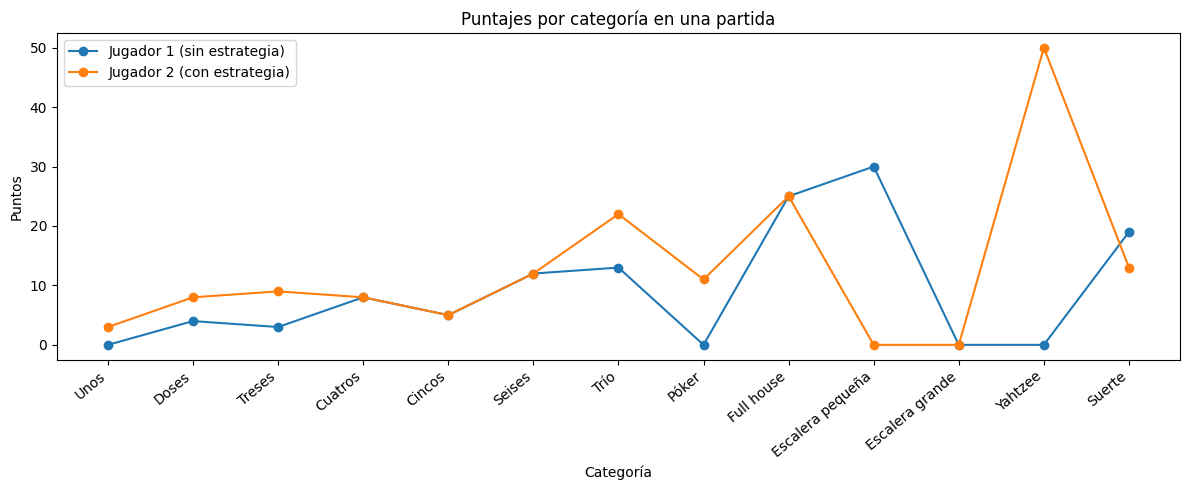

In [ ]:
# Junta las puntuaciones de ambos jugadores en una sola tabla.
tabla_marcador = pd.DataFrame({
    "Categoría": CATEGORIAS,
    "Jugador 1 (sin estrategia)": [
        puntajes_jugador_1[categoria] for categoria in CATEGORIAS
    ],
    "Jugador 2 (con estrategia)": [
        puntajes_jugador_2[categoria] for categoria in CATEGORIAS
    ],
})

total_jugador_1 = sum(puntajes_jugador_1.values())
total_jugador_2 = sum(puntajes_jugador_2.values())

display(tabla_marcador)
print(f"Total del Jugador 1, sin estrategia: {total_jugador_1}")
print(f"Total del Jugador 2, con estrategia: {total_jugador_2}")

if total_jugador_1 > total_jugador_2:
    print("Ganador de esta partida: Jugador 1")
elif total_jugador_2 > total_jugador_1:
    print("Ganador de esta partida: Jugador 2")
else:
    print("Resultado de esta partida: empate")

# Gráfica de puntos por categoría, como resumen visual de la partida.
tabla_marcador_larga = tabla_marcador.melt(
    id_vars="Categoría",
    var_name="Jugador",
    value_name="Puntos",
)

plt.figure(figsize=(12, 5))
for nombre_jugador, datos in tabla_marcador_larga.groupby("Jugador"):
    plt.plot(
        datos["Categoría"],
        datos["Puntos"],
        marker="o",
        label=nombre_jugador,
    )

plt.title("Puntajes por categoría en una partida")
plt.xlabel("Categoría")
plt.ylabel("Puntos")
plt.xticks(rotation=40, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Una partida no basta para comparar las estrategias

El marcador muestra quién ganó esta partida y cuántos puntos hizo cada jugador. Pero una sola partida depende de la suerte: cualquiera de los dos puede ganar.

Para comparar mejor las estrategias, ahora repetiremos muchos intentos y contaremos cuántas veces aparece Yahtzee con cada una.


## 5. Repetir los intentos y contar los Yahtzees

Un éxito es un intento en el que apareció Yahtzee. La probabilidad observada se calcula así:

**cantidad de intentos con Yahtzee ÷ cantidad total de intentos**

Por ejemplo, 20 éxitos en 500 intentos equivalen a 20 ÷ 500 = 0,04, es decir, 4 %.

In [ ]:
def ejecutar_intentos(estrategia, cantidad, semilla):
    # Ejecuta varios intentos y guarda si cada uno tuvo Yahtzee.
    rng = random.Random(semilla)
    resultados = []

    for _ in range(cantidad):
        # True significa que hubo Yahtzee; False significa que no hubo.
        resultados.append(estrategia(rng))

    return resultados


# Ejecuta 5.000 intentos para cada estrategia, con secuencias reproducibles.
resultados_sin_estrategia = ejecutar_intentos(
    intentar_sin_estrategia,
    TOTAL_INTENTOS,
    SEMILLA,
)
resultados_con_estrategia = ejecutar_intentos(
    intentar_con_estrategia,
    TOTAL_INTENTOS,
    SEMILLA + 1,
)


def probabilidad_acumulada(resultados, cantidad):
    # Cuenta los éxitos de los primeros N intentos y divide por N.
    exitos = sum(resultados[:cantidad])
    return exitos / cantidad


# Compara el porcentaje observado en cada cantidad de intentos.
tabla_resultados = pd.DataFrame({
    "Intentos": CANTIDADES_INTENTOS,
    "Sin estrategia (%)": [
        100 * probabilidad_acumulada(resultados_sin_estrategia, cantidad)
        for cantidad in CANTIDADES_INTENTOS
    ],
    "Con estrategia (%)": [
        100 * probabilidad_acumulada(resultados_con_estrategia, cantidad)
        for cantidad in CANTIDADES_INTENTOS
    ],
})

display(tabla_resultados.round(2))

,Intentos,Sin estrategia (%),Con estrategia (%)
0,10,0.00,0.0
1,50,0.00,10.0
2,100,0.00,6.0
3,500,0.20,5.0
4,1000,0.10,3.7
5,5000,0.18,4.4


## 6. Ver los resultados en una gráfica

Cada línea muestra el porcentaje de intentos que terminaron en Yahtzee. Si la línea con estrategia queda más alta, en este experimento esa forma de jugar consiguió Yahtzee más veces.

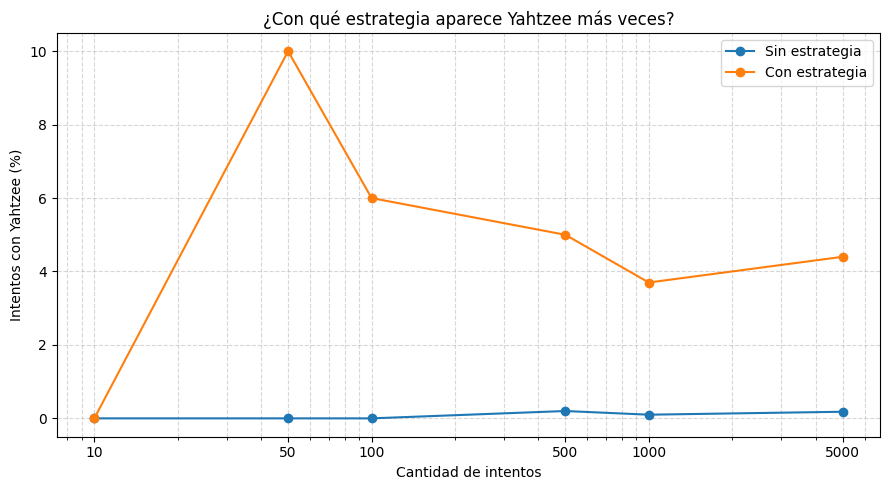

In [ ]:
plt.figure(figsize=(9, 5))

# Dibuja la probabilidad observada sin estrategia.
plt.plot(
    tabla_resultados["Intentos"],
    tabla_resultados["Sin estrategia (%)"],
    marker="o",
    label="Sin estrategia",
)

# Dibuja la probabilidad observada con la estrategia de guardar la cara más repetida.
plt.plot(
    tabla_resultados["Intentos"],
    tabla_resultados["Con estrategia (%)"],
    marker="o",
    label="Con estrategia",
)

plt.title("¿Con qué estrategia aparece Yahtzee más veces?")
plt.xlabel("Cantidad de intentos")
plt.ylabel("Intentos con Yahtzee (%)")
plt.xscale("log")
plt.xticks(CANTIDADES_INTENTOS, labels=[str(n) for n in CANTIDADES_INTENTOS])
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

## 7. Cómo interpretar los resultados

- **Monte Carlo:** repetimos muchas veces cada manera de jugar y contamos cuántas veces salió Yahtzee.
- **Ley de los Grandes Números:** con pocos intentos, el porcentaje puede cambiar mucho. Al sumar más intentos, suele volverse más estable.
- **Estrategia:** conservar los dados que más se repiten puede ayudar a juntar cinco iguales antes de que se acaben las tiradas.

La estrategia no cambia las probabilidades del dado. Cambia qué hacemos con los resultados que ya salieron. La gráfica muestra lo ocurrido en estos intentos; no garantiza que cada partida futura tenga el mismo resultado.